# Análise da segurança pública de Joinville/SC

SENAI/LAB365 — Visualização de Dados e BI. Execute as células em ordem, com o kernel da `.venv`.
Cada célula é uma etapa; as explicações estão nos comentários `#` e os resultados saem de `print()` e `display()`.

- **Sinesp/MJSP** (etapas 2 a 11): base aprovada, 911 observações, 12 séries, janeiro/2020 a setembro/2026 (PRF até agosto).
- **SSP/SC** (etapas 12 a 15): investigação **separada** de violência doméstica, em validação. Não foi identificada uma definição operacional de "Fato Comunicado" nos documentos analisados (isso não significa que a definição não exista oficialmente); por isso a unidade não é lida como vítima nem como ocorrência única.
- As duas fontes nunca são somadas nem unidas. O [README](../README.md) reúne fontes, regras e pendências.

**Como avaliar:** este arquivo foi salvo com os resultados da execução completa no computador do autor, com os XLSX e PDFs originais; as tabelas e os gráficos aparecem sem executar nada. Executado a partir de uma cópia do GitHub, ele funciona só com a base pública `dashboard/data_publica/`: a etapa 3 e as etapas 12 a 15 mostram um aviso, porque os arquivos originais não acompanham o repositório, e nenhum valor é estimado.

**Painel interativo (separado do notebook):** [abrir no Streamlit Cloud](https://seguranca-publica-joinville-sinesp.streamlit.app/) · programa `scripts/painel_streamlit.py` · execução local no terminal: `.\.venv\Scripts\python.exe -m streamlit run scripts/painel_streamlit.py`.

In [1]:
# ETAPA 1 — Bibliotecas e pastas
import hashlib
import sys
from pathlib import Path

import pandas as pd

# O notebook roda dentro da pasta notebooks/; a pasta-raiz entra no caminho do Python para importar os módulos do projeto.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from dashboard import calculos, graficos            # cálculos e gráficos já validados (os mesmos do painel)
from dashboard import dados_publicos as dp          # leitura e conferência da base aprovada
from src.pipeline import atualizacao_dados as au    # leitura do XLSX oficial

pasta_xlsx = RAIZ / "dados" / "brutos" / "sinesp"   # XLSX oficiais (originais, fora do Git)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)
%matplotlib inline

# Mostra a versão do pandas e só o nome da pasta do projeto (o caminho completo do computador não aparece).
print(f"Pandas {pd.__version__} | pasta do projeto: {RAIZ.name}")

Pandas 3.0.6 | pasta do projeto: Seguranca Publica Joinville


In [2]:
# ETAPA 2 — Leitura da base Sinesp aprovada
# É o CSV publicado no painel (recorte de Joinville/SC). dp.carregar_sinesp() lê com pd.read_csv e confere colunas, tipos e regras.
dados_sinesp = dp.carregar_sinesp()
manifesto = dp.carregar_manifesto()

print(f"Base aprovada: {dados_sinesp.shape[0]} observações × {dados_sinesp.shape[1]} colunas")
print(f"Versão dos dados: {manifesto['versao']}")
# O manifesto guarda o SHA-256 do CSV; sha256_normalizado calcula o mesmo valor para conferirmos que o arquivo não mudou.
hash_csv = dp.sha256_normalizado((dp.DIRETORIO_DADOS / dp.ARQ_SINESP).read_bytes())
hash_manifesto = next(f["sha256"] for f in manifesto["arquivos"] if f["arquivo"] == dp.ARQ_SINESP)
print(f"SHA-256 do CSV confere com o manifesto: {hash_csv == hash_manifesto}")
# head() mostra as 5 primeiras linhas da tabela; display() exibe a tabela formatada.
display(dados_sinesp.head())

Base aprovada: 911 observações × 6 colunas
Versão dos dados: 20261027T114400Z
SHA-256 do CSV confere com o manifesto: True


,ano,mes,evento,abrangencia,unidade,valor
0,2020,1,Feminicídio,Estadual,vítimas,0
1,2020,2,Feminicídio,Estadual,vítimas,0
2,2020,3,Feminicídio,Estadual,vítimas,1
3,2020,4,Feminicídio,Estadual,vítimas,1
4,2020,5,Feminicídio,Estadual,vítimas,0


In [3]:
# ETAPA 3 — XLSX oficial de 2026 (opcional): leitura e inspeção bruta
# O ETL (scripts/etl_joinville.py) lê os sete XLSX. Aqui lemos só o de 2026 para mostrar como a fonte original chega.
# Só usamos o arquivo cujo SHA-256 é o registrado no manifesto da base aprovada.
hash_2026 = manifesto["origem_dos_dados"]["sinesp_xlsx_sha256"]["2026"]
dados_brutos_2026 = None
if pasta_xlsx.is_dir():
    for caminho in sorted(pasta_xlsx.rglob("bancovde-2026.xlsx")):
        if hashlib.sha256(caminho.read_bytes()).hexdigest() == hash_2026:
            # ler_sinesp_xlsx devolve só as linhas de SC/JOINVILLE, com as 14 colunas originais.
            dados_brutos_2026 = au.ler_sinesp_xlsx(caminho)
            break

if dados_brutos_2026 is None:
    # Sem o arquivo oficial não há inspeção bruta: a análise segue com a base aprovada (dado derivado, não bruto).
    print("MODO DEMONSTRAÇÃO: XLSX oficial de 2026 não encontrado; a análise segue com a base aprovada.")
else:
    print(f"XLSX 2026 lido: {len(dados_brutos_2026)} linhas de Joinville")
    # Na fonte, a data é um número (serial do Excel); total_vitima traz as vítimas e total traz os mandados.
    dados_brutos_2026.info()
    display(dados_brutos_2026.head())

XLSX 2026 lido: 107 linhas de Joinville
<class 'pandas.DataFrame'>
RangeIndex: 107 entries, 0 to 106
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   uf               107 non-null    str    
 1   municipio        107 non-null    str    
 2   evento           107 non-null    str    
 3   data_referencia  107 non-null    int64  
 4   agente           0 non-null      object 
 5   arma             0 non-null      object 
 6   faixa_etaria     0 non-null      object 
 7   feminino         80 non-null     float64
 8   masculino        80 non-null     float64
 9   nao_informado    80 non-null     float64
 10  total_vitima     89 non-null     float64
 11  total            18 non-null     float64
 12  total_peso       0 non-null      object 
 13  abrangencia      107 non-null    str    
dtypes: float64(5), int64(1), object(4), str(4)
memory usage: 17.0+ KB


,uf,municipio,evento,data_referencia,agente,arma,faixa_etaria,feminino,masculino,nao_informado,total_vitima,total,total_peso,abrangencia
0,SC,JOINVILLE,Feminicídio,46023,None,None,None,0.0,0.0,0.0,0.0,NaN,None,Estadual
1,SC,JOINVILLE,Feminicídio,46054,None,None,None,0.0,0.0,0.0,0.0,NaN,None,Estadual
2,SC,JOINVILLE,Feminicídio,46082,None,None,None,0.0,0.0,0.0,0.0,NaN,None,Estadual
3,SC,JOINVILLE,Feminicídio,46113,None,None,None,0.0,0.0,0.0,0.0,NaN,None,Estadual
4,SC,JOINVILLE,Feminicídio,46143,None,None,None,0.0,0.0,0.0,0.0,NaN,None,Estadual


In [4]:
# ETAPA 4 — Tratamento: tipos e unidades
# No ETL cada linha original virou uma observação com ano, mes, evento, abrangencia, unidade e valor.
# Vítimas e mandados são unidades diferentes e nunca são somadas.
# dtypes mostra o tipo de cada coluna: Int64 = número inteiro que aceita ausência (<NA>); str = texto.
print(dados_sinesp.dtypes)
print()
# value_counts conta quantas observações há de cada unidade.
print(dados_sinesp["unidade"].value_counts())
# Int64 (I maiúsculo) aceita valor ausente (<NA>) sem trocá-lo por número.
print(f"\nTipo da coluna valor: {dados_sinesp['valor'].dtype}")

ano            Int64
mes            Int64
evento           str
abrangencia      str
unidade          str
valor          Int64
dtype: object

unidade
vítimas                                    809
mandados cumpridos (contagem publicada)    102
Name: count, dtype: int64

Tipo da coluna valor: Int64


In [5]:
# ETAPA 5 — Verificação de duplicidades
# Cada série (evento × abrangência) deve ter UMA observação por mês. Nenhuma linha é apagada.
# Se houvesse repetição, ela seria investigada (o Sinesp só admite parcelas somadas em Tentativa de homicídio e Estupro).
chave_observacao = ["evento", "abrangencia", "ano", "mes"]
repetidas = dados_sinesp.duplicated(subset=chave_observacao, keep=False)
print(f"Observações com chave repetida: {int(repetidas.sum())}")
print(f"Linhas totalmente idênticas: {int(dados_sinesp.duplicated().sum())}")

Observações com chave repetida: 0
Linhas totalmente idênticas: 0


In [6]:
# ETAPA 6 — Valores ausentes e zeros
# Zero publicado = a fonte informou 0 no mês (observação válida). Ausente (<NA>) = a fonte não informou; nunca vira zero.
print(f"Valores ausentes: {int(dados_sinesp['valor'].isna().sum())}")
print(f"Zeros publicados: {int(dados_sinesp['valor'].eq(0).sum())}")

# Zeros por série: eventos raros (latrocínio, feminicídio) têm muitos meses com zero.
dados_com_zero = dados_sinesp.assign(zero=dados_sinesp["valor"].eq(0))
zeros_por_serie = dados_com_zero.groupby(["evento", "abrangencia"])["zero"].sum()
display(zeros_por_serie.sort_values(ascending=False).to_frame("meses com zero"))

Valores ausentes: 0
Zeros publicados: 401


,,meses com zero
evento,abrangencia,
Mortes a esclarecer (sem indício de crime),Estadual,81
Roubo seguido de morte (latrocínio),Estadual,78
Lesão corporal seguida de morte,Estadual,74
Feminicídio,Estadual,67
Tentativa de feminicídio,Estadual,41
Mortes no trânsito,Polícia Rodoviária Federal,31
Mandado de prisão cumprido,Polícia Federal,12
Morte no trânsito ou em decorrência dele (exceto homicídio doloso),Estadual,9
Homicídio doloso,Estadual,4


In [7]:
# ETAPA 7 — Recorte de Joinville e cobertura das séries
# Toda a base é de Joinville/SC. O catálogo mostra o primeiro e o último mês de cada série.
# A PRF termina em agosto/2026 e os mandados da Polícia Federal começam em janeiro/2025.
catalogo = dp.carregar_catalogo_sinesp()
print(f"Séries no catálogo: {len(catalogo)}")
# A lista entre colchetes duplos seleciona só estas colunas do catálogo, nesta ordem.
display(catalogo[["evento", "abrangencia", "unidade", "inicio", "fim", "meses_observados", "meses_valor_zero"]])

Séries no catálogo: 12


,evento,abrangencia,unidade,inicio,fim,meses_observados,meses_valor_zero
0,Feminicídio,Estadual,vítimas,2020-01,2026-09,81,67
1,Homicídio doloso,Estadual,vítimas,2020-01,2026-09,81,4
2,Lesão corporal seguida de morte,Estadual,vítimas,2020-01,2026-09,81,74
3,Mandado de prisão cumprido,Estadual,mandados cumpridos (contagem publicada),2020-01,2026-09,81,1
4,Mandado de prisão cumprido,Polícia Federal,mandados cumpridos (contagem publicada),2025-01,2026-09,21,12
5,Morte no trânsito ou em decorrência dele (exce...,Estadual,vítimas,2020-01,2026-09,81,9
6,Mortes a esclarecer (sem indício de crime),Estadual,vítimas,2020-01,2026-09,81,81
7,Mortes no trânsito,Polícia Rodoviária Federal,vítimas,2020-01,2026-08,80,31
8,Roubo seguido de morte (latrocínio),Estadual,vítimas,2020-01,2026-09,81,78
9,Suicídio,Estadual,vítimas,2020-01,2026-09,81,1


In [8]:
# ETAPA 8 — Estatísticas descritivas (homicídio doloso, Estadual)
# Descrevem os valores MENSAIS: soma, média, mediana, mínimo, máximo e desvio-padrão (ddof=0: descreve os meses observados).
INDICADOR = "Homicídio doloso"
ABRANGENCIA = "Estadual"
ANOS = list(range(2020, 2027))

serie = calculos.serie_sinesp(dados_sinesp, INDICADOR, ABRANGENCIA)
resumo = calculos.resumo_serie_sinesp(serie)
display(pd.Series(resumo).to_frame("valor"))

# Quartis: Q1 e Q3 são os valores abaixo dos quais ficam 25% e 75% dos meses; IQR = Q3 − Q1.
quartis = calculos.quartis_iqr(serie["valor"])
print(f"Q1 = {quartis['q1']} | mediana = {quartis['mediana']} | Q3 = {quartis['q3']} | IQR = {quartis['iqr']}")
print(f"Média mensal {resumo['media_mensal']:.2f} e mediana {resumo['mediana_mensal']:.0f}: poucos meses muito altos puxam a média.")

,valor
meses_observados,81.000000
meses_com_valor,81.000000
meses_sem_valor,0.000000
meses_valor_zero,4.000000
soma,318.000000
media_mensal,3.925926
mediana_mensal,3.000000
minimo,0.000000
maximo,19.000000
desvio_padrao_ddof0,2.783451


Q1 = 2.0 | mediana = 3.0 | Q3 = 5.0 | IQR = 3.0
Média mensal 3.93 e mediana 3: poucos meses muito altos puxam a média.


In [9]:
# ETAPA 9 — Totais anuais e períodos equivalentes
# Só os anos completos (12 meses) recebem total anual; 2026 é parcial.
tabela_anual = calculos.tabela_anual_sinesp(serie)
display(tabela_anual[["ano", "cobertura", "meses_presentes", "soma"]])

# Para comparar 2026 com os outros anos, usamos o mesmo período: janeiro até o último mês publicado (setembro).
mes_final = calculos.mes_final_da_serie(serie)
periodos = calculos.comparacao_periodo_sinesp(serie, mes_final)
display(periodos[["ano", "periodo", "soma"]])

# Interpretação calculada direto das tabelas (descreve as contagens; não explica causas).
# set_index("ano") usa o ano como índice: total_por_ano[2020] devolve o total de 2020.
total_por_ano = tabela_anual.set_index("ano")["soma"]
total_periodo = periodos.set_index("ano")["soma"]
print(f"Anos completos: {int(total_por_ano[2020])} vítimas em 2020 e {int(total_por_ano[2025])} em 2025 "
      f"(com oscilações: {int(total_por_ano[2022])} em 2022 e {int(total_por_ano[2023])} em 2023).")
print(f"Janeiro–setembro: {int(total_periodo[2025])} vítimas em 2025 e {int(total_periodo[2026])} em 2026 "
      f"(diferença de {int(total_periodo[2026] - total_periodo[2025])}).")

,ano,cobertura,meses_presentes,soma
0,2020,ano completo,12,62
1,2021,ano completo,12,62
2,2022,ano completo,12,49
3,2023,ano completo,12,55
4,2024,ano completo,12,36
5,2025,ano completo,12,29
6,2026,parcial janeiro–setembro,9,25


,ano,periodo,soma
0,2020,janeiro–setembro,53
1,2021,janeiro–setembro,46
2,2022,janeiro–setembro,34
3,2023,janeiro–setembro,47
4,2024,janeiro–setembro,25
5,2025,janeiro–setembro,21
6,2026,janeiro–setembro,25


Anos completos: 62 vítimas em 2020 e 29 em 2025 (com oscilações: 49 em 2022 e 55 em 2023).
Janeiro–setembro: 21 vítimas em 2025 e 25 em 2026 (diferença de 4).


In [10]:
# ETAPA 10 — Outliers pelo método IQR (limites de Tukey)
# Limite inferior = Q1 − 1,5·IQR; limite superior = Q3 + 1,5·IQR. Meses fora deles são atípicos ESTATÍSTICOS, não erros comprovados.
diagnostico = calculos.diagnostico_outliers_iqr(serie)
print(f"{diagnostico['rotulo']} — {diagnostico['mensagem']}")
print(f"Limites: {diagnostico['limite_inferior']} a {diagnostico['limite_superior']} | meses fora: {diagnostico['n_fora']}")
display(diagnostico["fora"])

# O método não serve para todas as séries (IQR igual a zero, maioria de zeros, contagens muito baixas).
diagnosticos = calculos.diagnostico_outliers_todas_as_series(dados_sinesp)
display(diagnosticos[["evento", "abrangencia", "meses", "zeros", "classificacao"]])
informativas = int(diagnosticos["classificacao"].eq("método informativo").sum())
print(f"Método informativo em {informativas} das {len(diagnosticos)} séries; nas demais nenhum mês é apontado como atípico.")

método informativo — Os limites de Tukey são informativos para esta série. Pontos fora deles são atípicos estatísticos em relação ao conjunto dos meses observados — não são prova de erro, de anomalia ou de mudança real; séries com tendência podem ter limites pouco representativos.
Limites: -2.5 a 9.5 | meses fora: 2


,ano,mes,valor,direcao
0,2020,1,10,acima
1,2023,1,19,acima


,evento,abrangencia,meses,zeros,classificacao
0,Feminicídio,Estadual,81,67,IQR igual a zero
1,Homicídio doloso,Estadual,81,4,método informativo
2,Lesão corporal seguida de morte,Estadual,81,74,IQR igual a zero
3,Mandado de prisão cumprido,Estadual,81,1,método informativo
4,Mandado de prisão cumprido,Polícia Federal,21,12,maioria de zeros publicados
5,Morte no trânsito ou em decorrência dele (exce...,Estadual,81,9,método informativo
6,Mortes a esclarecer (sem indício de crime),Estadual,81,81,distribuição degenerada
7,Mortes no trânsito,Polícia Rodoviária Federal,80,31,contagens muito baixas
8,Roubo seguido de morte (latrocínio),Estadual,81,78,IQR igual a zero
9,Suicídio,Estadual,81,1,método informativo


Método informativo em 5 das 12 séries; nas demais nenhum mês é apontado como atípico.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


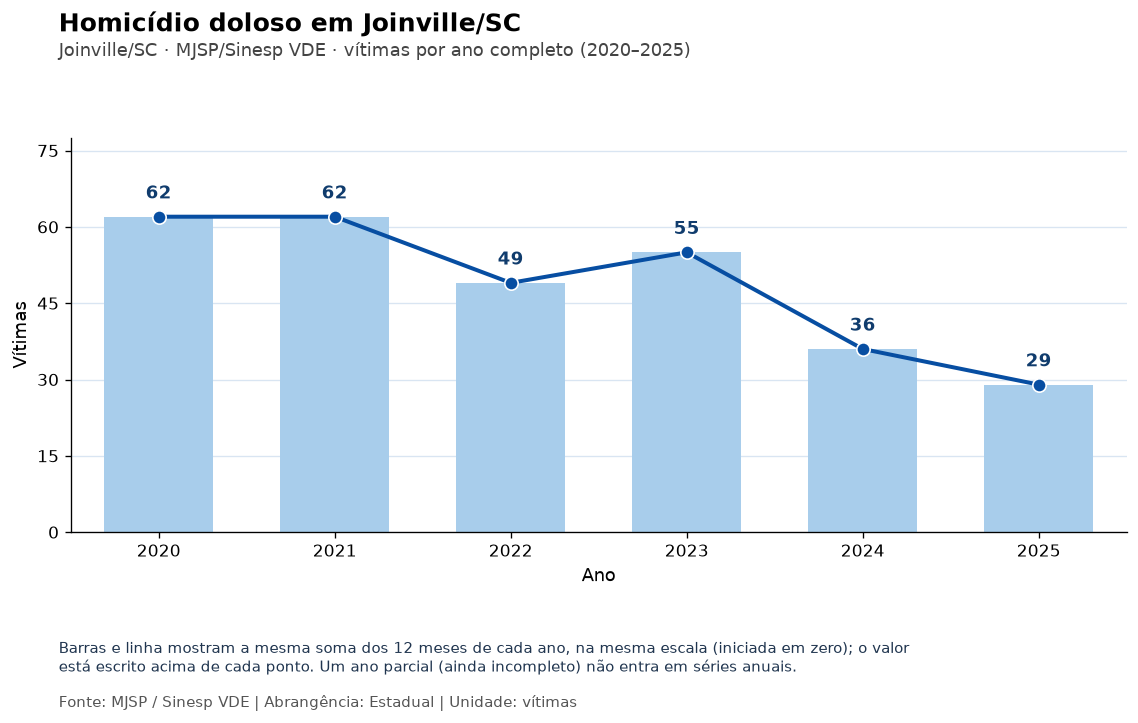

Anual: 62 vítimas em 2020 e 29 em 2025; 2026 aparece como parcial.


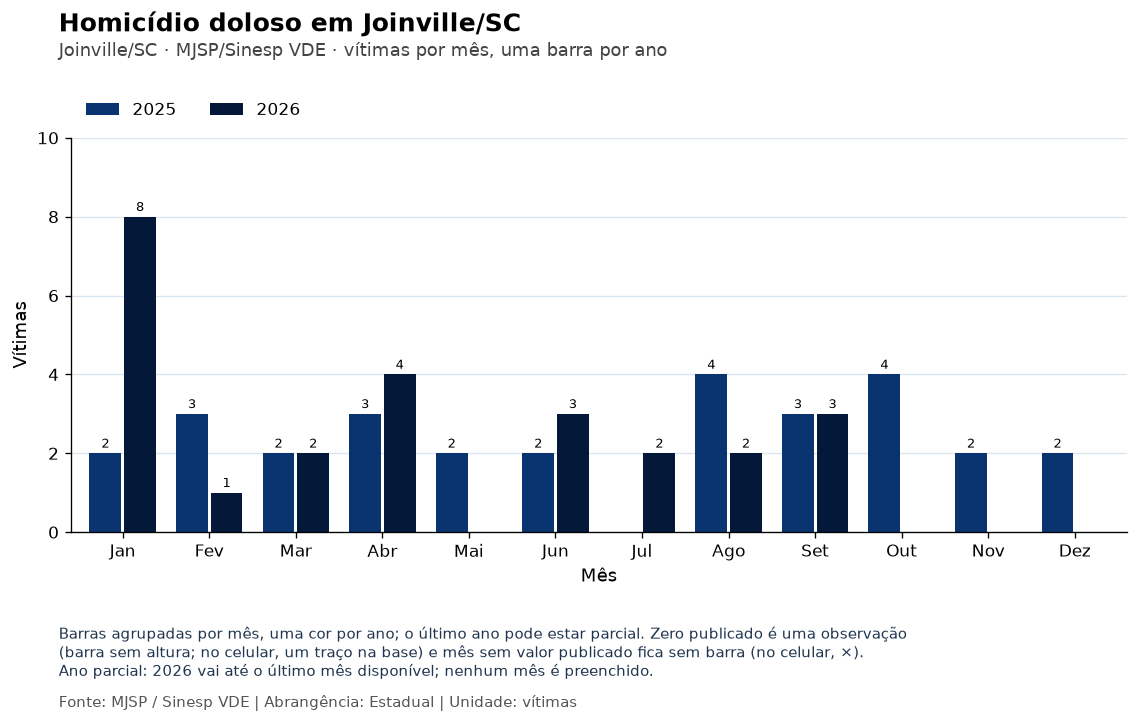

Mensal: contagens pequenas oscilam bastante; a comparação correta é entre períodos de mesma duração.


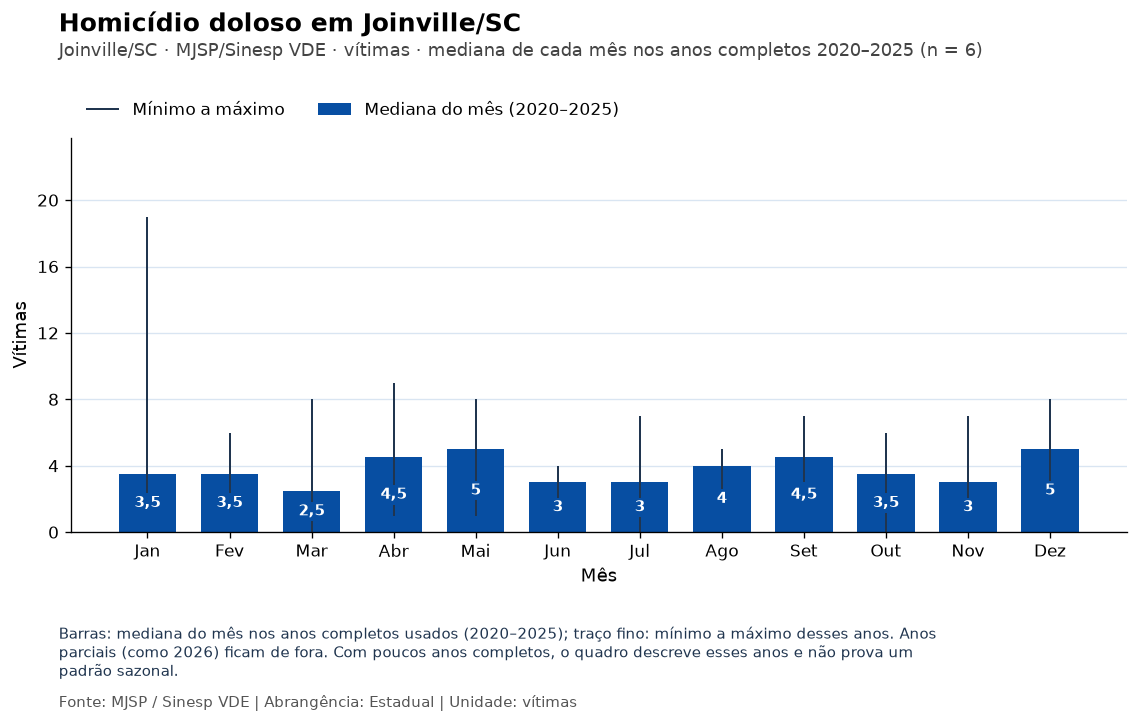

Perfil mensal: usa 6 anos completos (2020–2025); descreve esses anos e não prova sazonalidade.


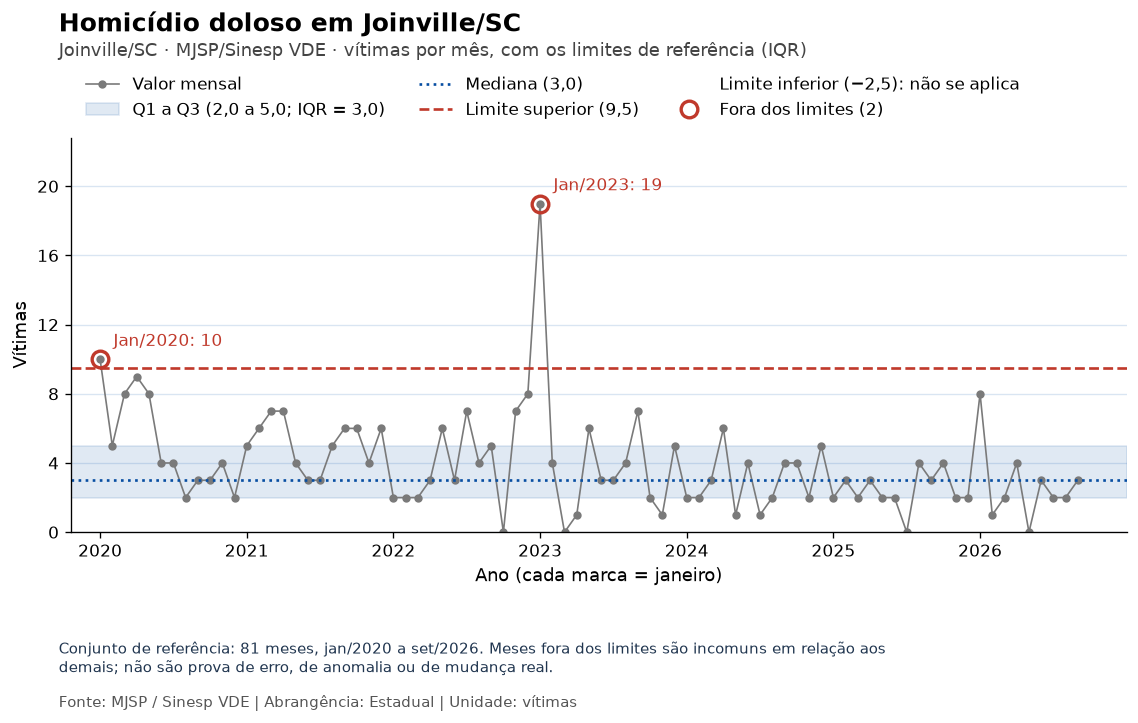

Outliers: 01/2020 (10), 01/2023 (19) acima do limite superior (9.5). São meses atípicos, não prova de erro.


In [11]:
# ETAPA 11 — Gráficos do Sinesp (os mesmos do painel)
# Evolução anual (barras).
display(graficos.figura_serie_anual_sinesp(dados_sinesp, INDICADOR, ABRANGENCIA, ANOS))
print(f"Anual: {int(total_por_ano[2020])} vítimas em 2020 e {int(total_por_ano[2025])} em 2025; 2026 aparece como parcial.")

# Evolução mensal de 2025 e 2026.
display(graficos.figura_mensal_sinesp(dados_sinesp, INDICADOR, ABRANGENCIA, [2025, 2026]))
print("Mensal: contagens pequenas oscilam bastante; a comparação correta é entre períodos de mesma duração.")

# Perfil por mês do ano (mediana), usando só os anos completos.
display(graficos.figura_sazonalidade_sinesp(dados_sinesp, INDICADOR, ABRANGENCIA, ANOS))
anos_usados = calculos.perfil_sazonal(serie).attrs["anos_usados"]
print(f"Perfil mensal: usa {len(anos_usados)} anos completos ({anos_usados[0]}–{anos_usados[-1]}); descreve esses anos e não prova sazonalidade.")

# Série mensal com os limites de Tukey.
display(graficos.figura_outliers_iqr_sinesp(dados_sinesp, INDICADOR, ABRANGENCIA, ANOS))
fora = diagnostico["fora"]
meses_fora = ", ".join(f"{int(l.mes):02d}/{int(l.ano)} ({int(l.valor)})" for l in fora.itertuples())
print(f"Outliers: {meses_fora} acima do limite superior ({diagnostico['limite_superior']}). São meses atípicos, não prova de erro.")

In [12]:
# ETAPA 12 — SSP/SC (fonte SEPARADA): leitura e conferência da violência doméstica
# Três relatórios oficiais (2023 e 2024). O módulo ssp_sc lê os PDFs, pareia as páginas e confere cada célula contra a tabela do PDF.
# Não foi identificada uma definição operacional de "Fato Comunicado" nos documentos analisados (isso não significa que a definição não exista oficialmente).
# Por isso a unidade não é lida como vítima nem como ocorrência única. Fonte em validação, fora do painel.
from IPython.display import Image
from src.pipeline import ssp_sc

resultado_ssp = None
if ssp_sc.acervo_disponivel():
    resultado_ssp = ssp_sc.processar()   # roda em memória: não grava nem altera nenhum dado
    vd = resultado_ssp["vd_extraida"]
    # Conferências: 216 células = 9 categorias × 24 meses, sem chave repetida e com 27 zeros publicados.
    assert len(vd) == 216 and not vd.duplicated(["ano", "mes", "categoria"]).any()
    assert vd["fatos_comunicados"].eq(0).sum() == 27
    assert resultado_ssp["verificacoes"]["ok"].all()
    print("SSP/SC: 216 células; 9 categorias; 24 meses; 27 zeros; unidade em validação.")
    print("Conferências aprovadas:", resultado_ssp["resumo"]["verificacoes_aprovadas"])
    # Cada valor guarda o PDF, a página, a tabela e a linha de origem. O CSV tratado não é publicado; por isso aparece só a contagem.
    print(f"Células localizadas no PDF de origem: {len(resultado_ssp['rastreabilidade'])}")
else:
    print("SSP/SC NÃO EXECUTADA: requer os 45 PDFs e 45 CSVs do acervo local. Nenhum valor foi estimado.")
    # Sem os originais, mostramos a figura-resumo já publicada (a mesma do painel no Streamlit Cloud), gerada pelo autor a partir dos PDFs.
    figura_resumo = RAIZ / "documentacao" / "graficos" / "analises" / "07-sspsc_violencia_domestica_2023_2024.png"
    if figura_resumo.is_file():
        display(Image(filename=str(figura_resumo)))

SSP/SC: 216 células; 9 categorias; 24 meses; 27 zeros; unidade em validação.
Conferências aprovadas: 159 de 159
Células localizadas no PDF de origem: 510


In [13]:
# ETAPA 13 — SSP/SC: estatísticas por categoria
# Somamos os 12 meses de cada categoria e ano. As categorias NÃO são somadas entre si.
if resultado_ssp is not None:
    grupos_vd = vd.groupby(["categoria", "ano"])["fatos_comunicados"]
    assert grupos_vd.count().eq(12).all()          # cada categoria/ano precisa ter exatamente 12 meses
    # unstack("ano") transforma os anos em colunas: uma linha por categoria, uma coluna para 2023 e outra para 2024.
    totais_vd = grupos_vd.sum(min_count=12).unstack("ano")
    totais_vd["diferença 2024 − 2023"] = totais_vd[2024] - totais_vd[2023]
    display(totais_vd.sort_values(2024, ascending=False))

    # Média, mediana, mínimo e máximo dos 24 meses; desvio-padrão com ddof=0 (descreve os meses observados).
    por_categoria = vd.groupby("categoria")["fatos_comunicados"]
    estatisticas_vd = por_categoria.agg(meses="count", media="mean", mediana="median", minimo="min", maximo="max")
    estatisticas_vd["desvio_padrao"] = por_categoria.std(ddof=0)
    display(estatisticas_vd.round(2))

ano,2023,2024,diferença 2024 − 2023
categoria,,,
Ameaça,1957,2085,128
Lesão corporal leve dolosa,989,959,-30
Injúria,541,716,175
Vias de fato,229,281,52
Difamação,190,211,21
Calúnia,109,119,10
Estupro,22,30,8
Lesão corporal grave ou gravíssima dolosa,19,10,-9
Injúria real,2,6,4


,meses,media,mediana,minimo,maximo,desvio_padrao
categoria,,,,,,
Ameaça,24,168.42,167.5,127,209,22.57
Calúnia,24,9.50,9.0,2,17,3.71
Difamação,24,16.71,17.0,6,24,4.57
Estupro,24,2.17,2.0,0,5,1.40
Injúria,24,52.38,51.5,33,78,12.13
Injúria real,24,0.33,0.0,0,2,0.55
Lesão corporal grave ou gravíssima dolosa,24,1.21,1.0,0,4,1.12
Lesão corporal leve dolosa,24,81.17,82.0,51,109,12.25
Vias de fato,24,21.25,19.5,13,32,5.59


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


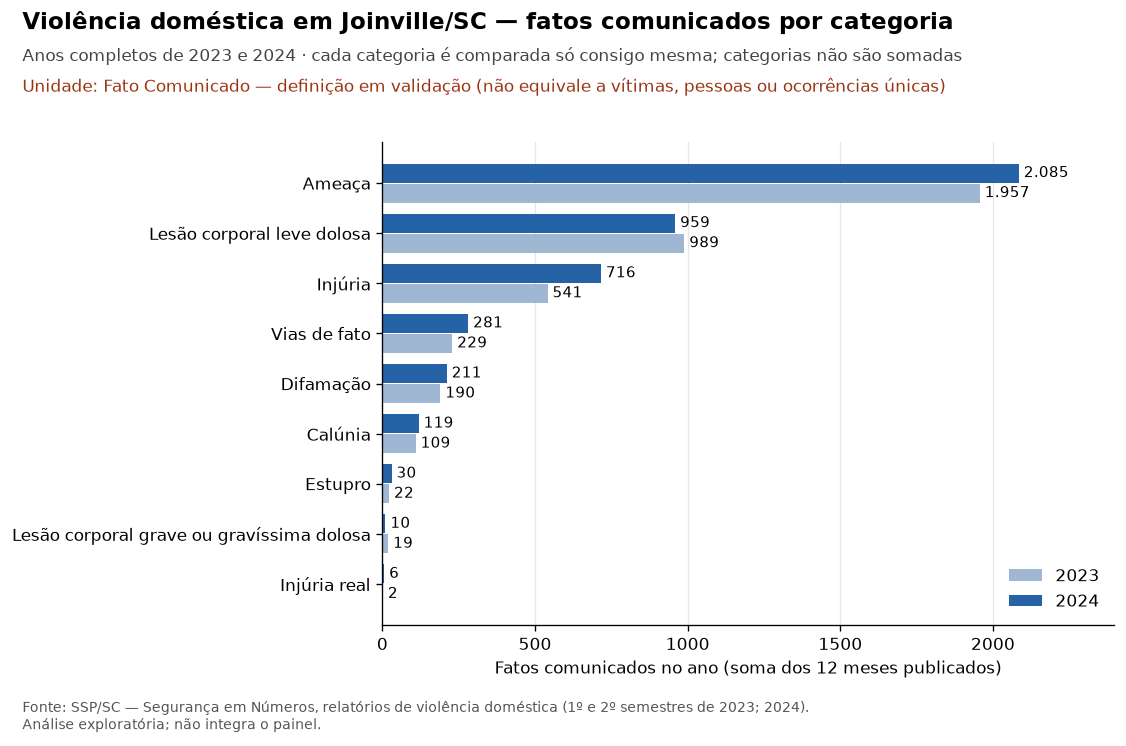

Ameaça: 1957 em 2023 e 2085 em 2024 fatos comunicados.
7 categorias têm mais registros em 2024 e 2 têm menos.
Isso descreve registros publicados; não demonstra variação do número de vítimas nem explica causas.


In [14]:
# ETAPA 14 — SSP/SC: gráfico de violência doméstica 2023 × 2024 e leitura
# Cada categoria é comparada apenas consigo mesma. Também fica salvo em documentacao/graficos/analises/07-... (não integra o painel).
if resultado_ssp is not None:
    display(ssp_sc.figura_violencia_domestica(vd))

    mais_em_2024 = int((totais_vd["diferença 2024 − 2023"] > 0).sum())
    menos_em_2024 = int((totais_vd["diferença 2024 − 2023"] < 0).sum())
    print(f"Ameaça: {int(totais_vd.loc['Ameaça', 2023])} em 2023 e {int(totais_vd.loc['Ameaça', 2024])} em 2024 fatos comunicados.")
    print(f"{mais_em_2024} categorias têm mais registros em 2024 e {menos_em_2024} têm menos.")
    print("Isso descreve registros publicados; não demonstra variação do número de vítimas nem explica causas.")

In [15]:
# ETAPA 15 — SSP/SC: rastreabilidade e republicações dos boletins de homicídio
# Os boletins publicam 294 valores em 58 grupos de republicação. Nenhuma versão é escolhida.
if resultado_ssp is not None:
    display(resultado_ssp["grupos"].groupby("classificacao").size().to_frame("grupos"))
    # Nos 30 valores publicados uma única vez, os campos de grupo ficam ausentes: nunca viram zero nem "não divergente".
    sem_grupo = resultado_ssp["versoes"]["grupo_republicacao"].isna()
    assert sem_grupo.sum() == 30
    assert resultado_ssp["versoes"].loc[sem_grupo, "grupo_divergente"].isna().all()
    # Nenhuma união definitiva Sinesp + SSP/SC foi gravada.
    assert not (RAIZ / "dados/processados/joinville_indicadores_consolidados.csv").exists()
    print("Conferido: 30 valores sem grupo continuam ausentes e não existe CSV consolidado das duas fontes.")

,grupos
classificacao,
Inconsistência ainda não explicada,37
Possível problema de cabeçalho,4
Sem divergência de valor,17


Conferido: 30 valores sem grupo continuam ausentes e não existe CSV consolidado das duas fontes.


In [16]:
# ETAPA 16 — Conclusões e limitações
print("CONCLUSÕES")
print(f"- Sinesp: homicídio doloso passou de {int(total_por_ano[2020])} vítimas (2020) para {int(total_por_ano[2025])} (2025) nos anos completos;")
print(f"  em janeiro–setembro, {int(total_periodo[2025])} (2025) e {int(total_periodo[2026])} (2026).")
print("- As séries são contagens mensais pequenas: a diferença absoluta é mais informativa que o percentual.")
print(f"- O critério IQR só é informativo em {informativas} das {len(diagnosticos)} séries.")
if resultado_ssp is not None:
    print("- SSP/SC: exploração separada de violência doméstica (fatos comunicados), extração rastreável e unidade em validação.")
else:
    print("- SSP/SC: não executada neste ambiente (acervo ausente).")

print("\nLIMITAÇÕES")
print("- Registros administrativos agregados: não medem toda a criminalidade, não estimam subnotificação e não indicam causa.")
print("- Sem taxas populacionais, bairro, horário ou corporação; sem total geral entre indicadores ou abrangências.")
print("- 2026 é parcial e a PRF termina antes das demais séries.")
print("- Furto, roubo, estupro e tráfico não existem no Sinesp de Joinville; publicações municipais divergem e não entram na base.")
print("- SSP/SC: não foi identificada uma definição operacional de 'Fato Comunicado' nos documentos analisados (isso não significa que a definição não exista oficialmente); versões de homicídio divergentes; fora do painel; sem soma com o Sinesp.")
print("- Próximos passos: esclarecer 'Fato Comunicado', resolver versões de homicídio e confirmar condições de reutilização.")

CONCLUSÕES
- Sinesp: homicídio doloso passou de 62 vítimas (2020) para 29 (2025) nos anos completos;
  em janeiro–setembro, 21 (2025) e 25 (2026).
- As séries são contagens mensais pequenas: a diferença absoluta é mais informativa que o percentual.
- O critério IQR só é informativo em 5 das 12 séries.
- SSP/SC: exploração separada de violência doméstica (fatos comunicados), extração rastreável e unidade em validação.

LIMITAÇÕES
- Registros administrativos agregados: não medem toda a criminalidade, não estimam subnotificação e não indicam causa.
- Sem taxas populacionais, bairro, horário ou corporação; sem total geral entre indicadores ou abrangências.
- 2026 é parcial e a PRF termina antes das demais séries.
- Furto, roubo, estupro e tráfico não existem no Sinesp de Joinville; publicações municipais divergem e não entram na base.
- SSP/SC: não foi identificada uma definição operacional de 'Fato Comunicado' nos documentos analisados (isso não significa que a definição não exista oficia